In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/raw")
csv_files = list(data_dir.glob("*.csv"))

print(f"CSV files found: {len(csv_files)}")

for file in csv_files:
    print(file.name, f"({file.stat().st_size / (1024 * 1024):.2f} MB)")

CSV files found: 3
NUSW-NB15_features.csv (0.00 MB)
UNSW_NB15_testing-set.csv (14.67 MB)
UNSW_NB15_training-set.csv (30.80 MB)


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data/raw")

train_path = DATA_DIR / "UNSW_NB15_training-set.csv"
test_path = DATA_DIR / "UNSW_NB15_testing-set.csv"
features_path = DATA_DIR / "NUSW-NB15_features.csv"

for path in [train_path, test_path, features_path]:
    print(f"{path.name}: {'Found' if path.exists() else 'NOT FOUND'}")

UNSW_NB15_training-set.csv: Found
UNSW_NB15_testing-set.csv: Found
NUSW-NB15_features.csv: Found


In [3]:
train_df = pd.read_csv(train_path, low_memory=False)
test_df = pd.read_csv(test_path, low_memory=False)

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nFirst five training records:")
display(train_df.head())

Training shape: (175341, 45)
Testing shape: (82332, 45)

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

First five training records:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [4]:
print("Training label distribution:")
display(train_df["label"].value_counts().rename(
    index={0: "Normal", 1: "Attack"}
))

if "attack_cat" in train_df.columns:
    print("\nAttack categories:")
    display(train_df["attack_cat"].value_counts(dropna=False))

Training label distribution:


label
Attack    119341
Normal     56000
Name: count, dtype: int64


Attack categories:


attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [5]:
print("Missing values in training data:")
display(
    train_df.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nInfinite values in numeric columns:")
numeric_df = train_df.select_dtypes(include=np.number)

infinite_counts = pd.Series(
    np.isinf(numeric_df).sum(),
    name="infinite_count"
)

display(infinite_counts[infinite_counts > 0])

print("\nDuplicate rows:", train_df.duplicated().sum())

print("\nData types:")
display(train_df.dtypes)

Missing values in training data:


id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
sttl       0
dttl       0
sload      0
dload      0
sloss      0
dtype: int64


Infinite values in numeric columns:


Series([], Name: infinite_count, dtype: int64)


Duplicate rows: 0

Data types:


id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

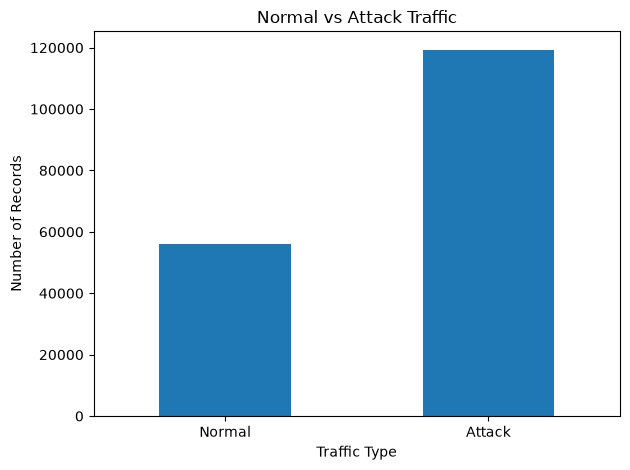

In [6]:
label_counts = train_df["label"].value_counts().sort_index()

label_counts.index = [
    "Normal" if label == 0 else "Attack"
    for label in label_counts.index
]

label_counts.plot(kind="bar")
plt.title("Normal vs Attack Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
print("Testing label distribution:")
display(test_df["label"].value_counts(dropna=False))

print("\nTesting attack categories:")
display(test_df["attack_cat"].value_counts(dropna=False))

print("\nDo training and testing columns match?")
print(train_df.columns.equals(test_df.columns))

Testing label distribution:


label
1    45332
0    37000
Name: count, dtype: int64


Testing attack categories:


attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


Do training and testing columns match?
True


In [8]:
features_df = pd.read_csv(
    features_path,
    header=None,
    encoding="cp1252"
).iloc[1:,1:]

features_df.columns = ["name","type","description"]

display(
    features_df.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal",
        "max-width": "600px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [("text-align", "left")]
        },
    ])
)

name,type,description
srcip,nominal,Source IP address
sport,integer,Source port number
dstip,nominal,Destination IP address
dsport,integer,Destination port number
proto,nominal,Transaction protocol
state,nominal,"Indicates to the state and its dependent protocol, e.g. ACC, CLO, CON, ECO, ECR, FIN, INT, MAS, PAR, REQ, RST, TST, TXD, URH, URN, and (-) (if not used state)"
dur,Float,Record total duration
sbytes,Integer,Source to destination transaction bytes
dbytes,Integer,Destination to source transaction bytes
sttl,Integer,Source to destination time to live value
